In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import torch

import lvr

import os

plt.style.use("mystyle")

# os.environ["DATA"] = r"C:\Users\FPGA designer\Documents\Adrien\DATA"
os.environ["DATA"] = r"../simulations/animals"

def load_metrics(name, num_epochs=30, return_test=False):
    filepath = "data/run_logs/finals"
    dfs = [
        pd.read_csv(f"{filepath}/{f}/metrics.csv").iloc[:num_epochs]
        for f in os.listdir(filepath)
        if f.startswith(f"animalsv3_{name}")
    ]
    datas = np.stack(
        [
            df["test_acc"].to_numpy()
            for df in dfs
        ]
    )

    if return_test:
        final_test_acc = np.array([
            df["val_acc"].iloc[-1]
            for df in dfs
        ])

        return datas, final_test_acc
    else:
        return datas

[WARNING] Power Supplies not connected


In [2]:
perceptron, perceptron_test = load_metrics("mac_32-4_", num_epochs=20, return_test=True)
perceptron_nomac, perceptron_nomac_test = load_metrics("32-4_", num_epochs=20, return_test=True)
mlp, mlp_test = load_metrics("32-48-4_", return_test=True)
ff, ff_test = load_metrics("36-48-48-bis_", num_epochs=30, return_test=True)
cf, cf_test = load_metrics("32-48-48_", num_epochs=30, return_test=True)

----
## Experimental Results

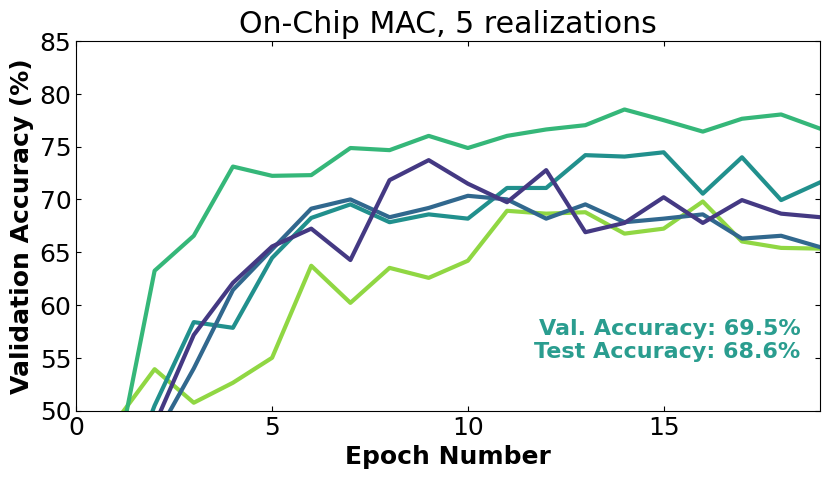

In [3]:

plt.figure(figsize=(2*4.8, 4.8))
for i, d in enumerate(perceptron):
    plt.plot(
        d * 100,
        color=cm.viridis_r((i + 1) / 6),
        # label="Hardware In-The-Loop" if i == 1 else None,
    )

plt.text(perceptron.shape[1] - 1.5, 55, f"Val. Accuracy: {np.mean(perceptron[:, -1])*100:.1f}%\nTest Accuracy: {np.mean(perceptron_test)*100:.1f}%", c="C2", ha="right", fontdict={"weight": "bold", "size": 16})
plt.xlim(0, 19)
plt.xticks(np.arange(0, 20, 5))
plt.ylim(50, 85)
plt.xlabel("Epoch Number", fontdict={"weight": "bold"})
plt.ylabel("Validation Accuracy (%)", fontdict={"weight": "bold"})
plt.title("On-Chip MAC, 5 realizations")
plt.savefig("plots_out/c_perceptron.svg", dpi=300, bbox_inches="tight")

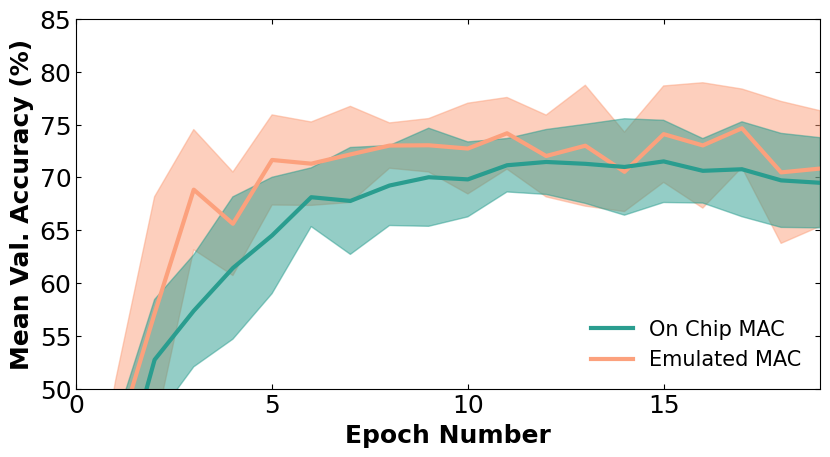

In [4]:
selected_perceptrons = [6, 26, 11, 30, 8] # np.random.choice(len(perceptron), 5) # Because 50 runs
perceptron_nomac = perceptron_nomac[selected_perceptrons]

plt.figure(figsize=(2*4.8, 4.8))


perceptron_plot, = plt.plot(np.mean(perceptron_nomac, axis=0) * 100, color="C0")
plt.fill_between(
    np.arange(20),
    (np.mean(perceptron_nomac, axis=0) - np.std(perceptron_nomac, axis=0)) * 100,
    (np.mean(perceptron_nomac, axis=0) + np.std(perceptron_nomac, axis=0)) * 100,
    color="C0",
    # linewidth=3,
    alpha=.5,
)

perceptron_mac_plot, = plt.plot(np.mean(perceptron, axis=0) * 100, color="C2")
plt.fill_between(
    np.arange(20),
    (np.mean(perceptron, axis=0) - np.std(perceptron, axis=0)) * 100,
    (np.mean(perceptron, axis=0) + np.std(perceptron, axis=0)) * 100,
    color="C2",
    # linewidth=3,
    alpha=.5,
)


plt.xlim(0, 19)
plt.xticks(np.arange(0, 20, 5))
plt.xlabel("Epoch Number", fontdict={"weight": "bold"})
plt.ylabel("Mean Val. Accuracy (%)", fontdict={"weight": "bold"})
plt.ylim(50, 85)
plt.legend([perceptron_mac_plot, perceptron_plot], ["On Chip MAC", "Emulated MAC"], loc="lower right")

# print(f"{np.mean(cf, axis=0)[-1] * 100:.2f} + {np.std(cf, axis=0)[-1] * 100:.2f}")
# print(f"{np.mean(perceptron_mac, axis=0)[-1] * 100:.2f} + {np.std(perceptron_mac, axis=0)[-1] * 100:.2f}")
plt.savefig("plots_out/d_mac_v_nomac.svg", dpi=300, bbox_inches="tight")

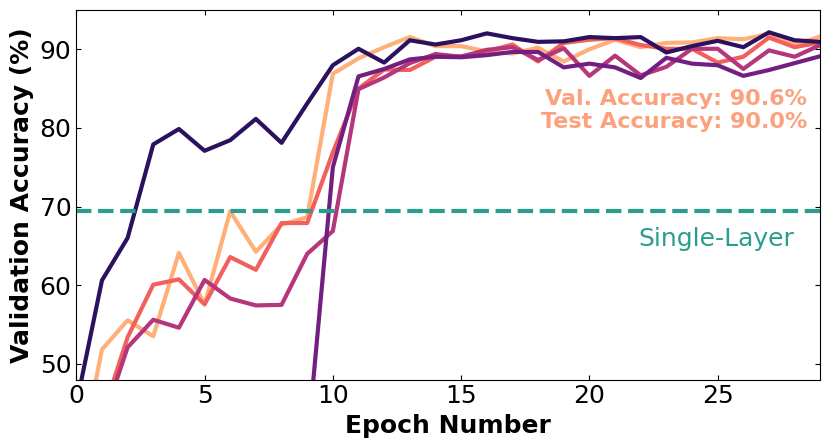

In [5]:
def plot_traces(data, cmap, ax=None, *, cmap_min_offset=1, cmap_max_offset=1):
  ax = ax or plt.gca()
  for i, d in enumerate(data):
    ax.plot(d * 100, color=cmap((i + cmap_min_offset) / (len(data) + cmap_max_offset)))

plt.figure(figsize=(2*4.8, 4.8))
plot_traces(mlp, cmap=cm.magma_r)
plt.axhline(perceptron.mean(axis=0)[-1]*100, linestyle="--", color="C2")
plt.text(28, 65, "Single-Layer", ha="right", color="C2")

plt.xlim(0, 29)
plt.ylim(48, 95)
plt.xlabel("Epoch Number", fontdict={"weight": "bold"})
plt.ylabel("Validation Accuracy (%)", fontdict={"weight": "bold"})
plt.text(mlp.shape[1] - 1.5, 80, f"Val. Accuracy: {np.mean(mlp[:, -1])*100:.1f}%\nTest Accuracy: {np.mean(mlp_test)*100:.1f}%", c="C0", ha="right", fontdict={"weight": "bold", "size": 16})
plt.savefig("plots_out/c_mpl_v_perceptron.svg", dpi=300, bbox_inches="tight")

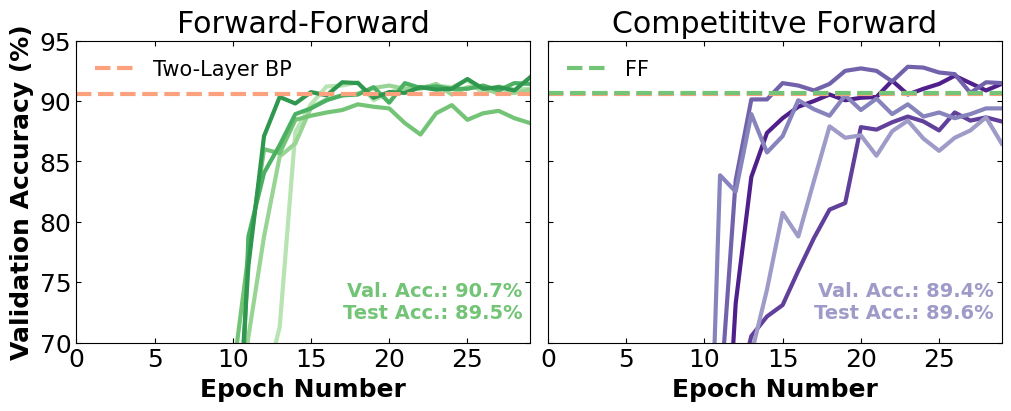

In [6]:
fig, axs = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(10,4), constrained_layout=True)

plot_traces(ff, cm.Greens, axs[0], cmap_min_offset=3, cmap_max_offset=5)
axs[0].text(ff.shape[1] - 1.5, 72, f"Val. Acc.: {np.mean(ff[:, -1])*100:.1f}%\nTest Acc.: {np.mean(ff_test)*100:.1f}%", c=cm.Greens(0.5), ha="right", fontdict={"weight": "bold", "size": 14})
plot_traces(cf, cm.Purples_r, axs[1], cmap_max_offset=5)
axs[1].text(cf.shape[1] - 1.5, 72, f"Val. Acc.: {np.mean(cf[:, -1])*100:.1f}%\nTest Acc.: {np.mean(cf_test)*100:.1f}%", c=cm.Purples_r(0.5), ha="right", fontdict={"weight": "bold", "size": 14})

axs[0].axhline(np.mean(mlp, axis=0)[-1] * 100, linestyle="--", color="C0", label="Two-Layer BP")
axs[1].axhline(np.mean(mlp, axis=0)[-1] * 100, linestyle="--", color="C0")
axs[1].axhline(np.mean(ff, axis=0)[-1] * 100, linestyle="--", color=cm.Greens(0.5), label="FF")

axs[0].set_xlim(0, 29)
axs[0].set_xticks(np.arange(0, 30, 5))
axs[0].set_ylim(70, 95)
axs[0].set_xlabel("Epoch Number", fontdict={"weight": "bold"})
axs[1].set_xlabel("Epoch Number", fontdict={"weight": "bold"})
axs[0].set_ylabel("Validation Accuracy (%)", fontdict={"weight": "bold"})
axs[0].set_title("Forward-Forward")
axs[1].set_title("Competititve Forward")
axs[0].legend(loc="upper left")
axs[1].legend(loc="upper left")
plt.savefig("plots_out/c_ff.svg", dpi=300, bbox_inches="tight")

In [7]:
(mlp_test*100).std(), (ff_test*100).std(), (cf_test*100).std()

(np.float64(1.1426669314647087),
 np.float64(1.4067004757138957),
 np.float64(1.843375167164948))

#### Statistical Tests for "Similar Accuracies"

In [8]:
from scipy.stats import ttest_ind
print("BP test accuracies:", ", ".join(map(lambda x: fr"{x:.2f}\%", mlp_test*100)))
print("FF test accuracies:", ", ".join(map(lambda x: fr"{x:.2f}\%", ff_test*100)))
print("CF test accuracies:", ", ".join(map(lambda x: fr"{x:.2f}\%", cf_test*100)))

print(f"mu_bp == mu_ff: {ttest_ind(mlp_test, ff_test, equal_var=False).pvalue:.3f}")
print(f"mu_bp == mu_cf: {ttest_ind(mlp_test, cf_test, equal_var=False).pvalue:.3f}")
print(f"mu_cf == mu_ff: {ttest_ind(cf_test, ff_test, equal_var=False).pvalue:.3f}")

print(f"mu_bp > mu_ff: {ttest_ind(mlp_test, ff_test, equal_var=False, alternative='less').pvalue:.3f}")
print(f"mu_bp > mu_cf: {ttest_ind(mlp_test, cf_test, equal_var=False, alternative='less').pvalue:.3f}")
print(f"mu_cf > mu_ff: {ttest_ind(cf_test, ff_test, equal_var=False, alternative='less').pvalue:.3f}")

BP test accuracies: 90.62\%, 91.18\%, 89.89\%, 87.87\%, 90.44\%
FF test accuracies: 88.05\%, 90.44\%, 87.68\%, 89.89\%, 91.36\%
CF test accuracies: 91.18\%, 90.62\%, 89.52\%, 90.44\%, 86.03\%
mu_bp == mu_ff: 0.586
mu_bp == mu_cf: 0.697
mu_cf == mu_ff: 0.951
mu_bp > mu_ff: 0.707
mu_bp > mu_cf: 0.652
mu_cf > mu_ff: 0.524


In [9]:
delta = 10/100
ttest_ind(mlp_test, [x - delta for x in cf_test], equal_var=False, alternative="greater").pvalue, ttest_ind(mlp_test, [x + delta for x in cf_test], equal_var=False, alternative="less").pvalue

# IF mu_bp <= mu_ff-delta% WRONG THEN mu_bp - mu_ff > - delta%
# IF mu_bp >= mu_ff+delta% WRONG THEN=> mu_bp - mu_ff < + delta%

(np.float64(1.854202435362012e-05), np.float64(3.218635344965191e-05))

In [ ]:
import json

def filter_used_conductances(gs, mmap, model, *, layer=[0,1]):
    if not isinstance(layer, list):
        layer = [layer]

    used = [np.zeros(p.shape) for _ in range(2) for p in model.parameters()]

    lvr.utils.map_memory(mmap, (0, 0), gs[:, ::2], used[:2])
    lvr.utils.map_memory(mmap, (0, 0), gs[:, 1::2], used[2:])

    if len(layer) == 1:
        return [used[layer[0]], used[layer[0] + 2]]
    else:
        return [used[layer[0]], used[layer[0] + 2], used[layer[1]], used[layer[1] + 2]]

def get_total_pulse(path, is_bp):
    # path = "data/run_logs/finals/animalsv3_36-48-48_1406_141129"
    with open(f"{path}/hyperparams.json", "r") as f:
        hps = json.load(f)
        arch = hps["arch"]
        num_layers = len(arch) - 1
        num_epochs = hps["num_epochs"]
        switch_epoch = hps["switch_epoch"]
        thresh = hps["grad_thresh"]
    
    if num_layers != 2:
        raise ValueError("Expected two layer network")
    
    model = lvr.utils.create_mlp(arch, lvr.utils.device)
    mmap = lvr.utils.load_memory_map(hps["memory_map"], model, lvr.utils.device)
    grads_dir_listing = os.listdir(f"{path}/raw_grads")
    num_total_steps = len(grads_dir_listing) // num_layers
    num_step_per_epoch = num_total_steps // num_epochs

    memristor_updates = [np.zeros((*np.load(f"{path}/raw_grads/e0s0l{layer}.npy").shape, 2)) for layer in range(num_layers)]
    memristor_conductances = []
    for e in range(num_epochs): #num_epochs
        for s in range(num_step_per_epoch): # num_step_per_epoch
            if is_bp:
                l = 1 if e < switch_epoch else 0
            else:
                l = 0 if e < switch_epoch else 1

            grads = np.load(f"{path}/raw_grads/e{e}s{s}l{l}.npy")
            conductances = filter_used_conductances(np.load(f"{path}/array_conductances/e{e}s{s}.npy"), mmap, model, layer=l)
            conductances = [gs.ravel() for gs in conductances]
            # print(list(map(lambda x:x.shape, conductances)))
            # print((grads > thresh[l]).ravel().nonzero()[0].max())
            memristor_updates[l][:, :, 0] += grads > thresh[l]
            memristor_updates[l][:, :, 1] += grads < -thresh[l]
            assert ((grads > thresh[l]).ravel().nonzero()[0].size == (grads > thresh[l]).ravel().sum())
            memristor_conductances.extend(conductances[0][(grads > thresh[l]).ravel().nonzero()[0]])
            memristor_conductances.extend(conductances[1][(grads < -thresh[l]).ravel().nonzero()[0]])

    return [update.ravel() for update in memristor_updates], np.asarray(memristor_conductances)

def load_total_pulses(name, is_bp):
    filepath = "data/run_logs/finals"
    datas = [
        get_total_pulse(f"{filepath}/{f}", is_bp)
        for f in os.listdir(filepath)
        if f.startswith(f"animalsv3_{name}")
    ]

    return datas

cf_total_pulses = load_total_pulses("32-48-48_", is_bp=False)
ff_total_pulses = load_total_pulses("36-48-48-bis_", is_bp=False)
mlp_total_pulses = load_total_pulses("32-48-4_", is_bp=True)

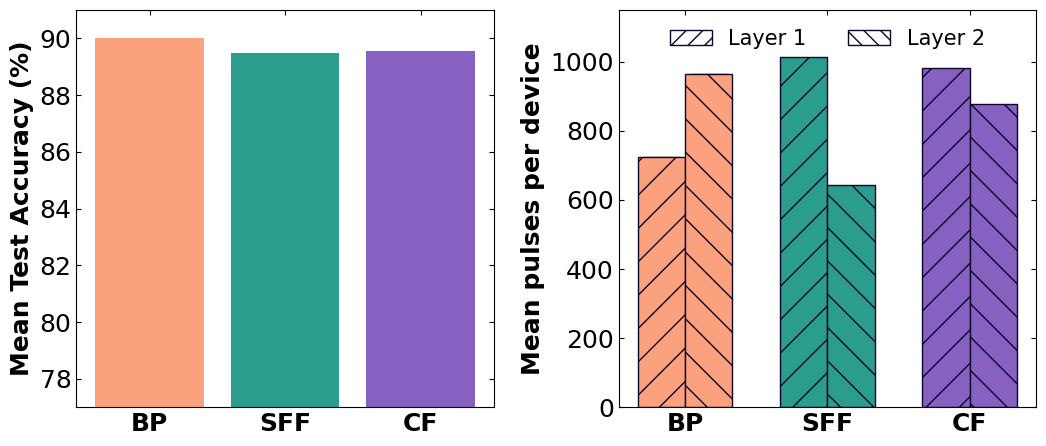

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(2.25*4.8,4.8))

axs[0].bar(
  [1, 2, 3],
  [
    mlp_test*100,
    ff_test*100,
    cf_test*100,
  ],
  color=["C0", "C2", "C1"]
)
axs[0].set_ylabel("Mean Test Accuracy (%)", fontdict={"weight": "bold"})
axs[0].set_ylim(77, 91)
axs[0].set_xticks([1,2,3], ["BP", "SFF", "CF"], fontdict={"weight": "bold"})

axs[1].bar(
  [1, 2, 4, 5, 7, 8],
  [
    np.mean([x[0][0].mean() for x in mlp_total_pulses]),
    np.mean([x[0][1].mean() for x in mlp_total_pulses]),
    np.mean([x[0][0].mean() for x in ff_total_pulses]),
    np.mean([x[0][1].mean() for x in ff_total_pulses]),
    np.mean([x[0][0].mean() for x in cf_total_pulses]),
    np.mean([x[0][1].mean() for x in cf_total_pulses]),
  ],
  facecolor=["C0","C0", "C2","C2", "C1","C1"],
  width=1,
  edgecolor="C4",
  hatch=["/", "\\"] * 3,
)
axs[1].bar(
    [1],
    [np.mean([x[0][0].mean() for x in mlp_total_pulses])],
    zorder=-10,
    color="white",
    edgecolor="C4",
    hatch="//",
    label="Layer 1"
)
axs[1].bar(
    [2],
    [np.mean([x[0][1].mean() for x in mlp_total_pulses])],
    zorder=-10,
    color="white",
    edgecolor="C4",
    hatch="\\\\",
    label="Layer 2"
)
axs[1].set_ylabel("Mean pulses per device", fontdict={"weight": "bold"})
axs[1].set_xticks([1.5,4.5,7.5], ["BP", "SFF", "CF"], fontdict={"weight": "bold"})
axs[1].set_ylim(0, 1150)
axs[1].legend(loc="upper center", ncols=2)
fig.tight_layout()
# plt.savefig("plots_out/e_pulse_count_bars.svg", dpi=300, bbox_inches="tight")

---
## Energy Estimates

In [ ]:
cf_tot_num_updates = np.sum([x[1].size for x in cf_total_pulses])
ff_tot_num_updates = np.sum([x[1].size for x in ff_total_pulses])
mlp_tot_num_updates = np.sum([x[1].size for x in mlp_total_pulses])

In [ ]:
print("ENERGY ESTIMATES")
print("===== CF =====")
mean_g = np.mean([x[1].mean() for x in cf_total_pulses])
print(f"{mean_g*1e6:.2f}µS per device before update in avg")
print(f"{np.mean([x[1].sum() for x in cf_total_pulses]) * 0.9**2 * 0.6e-6 * 1e6:.2f}µJ for writes vs {cf_tot_num_updates*387e-12 * 1e3:.2f}mJ with W&V")
print(f"{np.mean([x[1].sum() for x in cf_total_pulses]) * 0.62**2 * 0.03e-6 * 1e6:.2f}µJ for writes on mac array")
print(f"{2*32*mean_g * 0.2**2 * 15e-6 * 4000*30 * 1e6:.1f}µJ for macs")

print("===== FF =====")
mean_g = np.mean([x[1].mean() for x in ff_total_pulses])
print(f"{np.mean([x[1].mean() for x in ff_total_pulses])*1e6:.2f}µS per device before update in avg")
print(f"{np.mean([x[1].sum() for x in ff_total_pulses]) * 0.9**2 * 0.6e-6 * 1e6:.2f}µJ for writes vs {ff_tot_num_updates*387e-12 * 1e3:.2f}mJ with W&V")
print(f"{2*32*mean_g * 0.2**2 * 15e-6 * 4000*30 * 1e6:.1f}µJ for macs")

print("===== BP =====")
mean_g = np.mean([x[1].mean() for x in mlp_total_pulses])
print(f"{np.mean([x[1].mean() for x in mlp_total_pulses])*1e6:.2f}µS per device before update in avg")
print(f"{np.mean([x[1].sum() for x in mlp_total_pulses]) * 0.9**2 * 0.6e-6 * 1e6:.2f}µJ for writes vs {mlp_tot_num_updates*387e-12 * 1e3:.2f}mJ with W&V")
print(f"{4*2*32*mean_g * 0.05**2 * 15e-6 * 4000*30 * 1e6:.1f}µJ for macs")

print("For writes: ∑G_i * U² * Δt; where G_i is the conductance of the device before applying pulse, summed over all updates of training")
print("For macs (very crude estimate, better one in paper): 2*32 * <G> * U² * Δt * n_epochs * n_examples; where <G> is the mean conductance of the all devices (for simplification), 2*32 for the input size, n_epochs=30, n_examples=4000")

ENERGY ESTIMATES
===== CF =====
72.94µS per device before update in avg
250.70µJ for writes vs 13.68mJ with W&V
5.95µJ for writes on mac array
336.1µJ for macs
===== FF =====
75.75µS per device before update in avg
238.30µJ for writes vs 12.53mJ with W&V
349.0µJ for macs
===== BP =====
81.07µS per device before update in avg
102.45µJ for writes vs 5.03mJ with W&V
93.4µJ for macs
For writes: ∑G_i * U² * Δt; where G_i is the conductance of the device before applying pulse, summed over all updates of training
For macs: 2*32 * <G> * U² * Δt * n_epochs * n_examples; where <G> is the mean conductance of the all devices (for simplification), 2*32 for the input size, n_epochs=30, n_examples=4000


In [11]:
dloader = lvr.utils.load_dataset(32, ternarize=True)[0]
propor_zeroinput = float(sum(map(lambda x: x[0].ravel().size(0) - torch.count_nonzero(x[0]), dloader)) / sum(map(lambda x: x[0].ravel().size(0), dloader)))
effective_number_inputs = 32 * (1-propor_zeroinput)
effective_number_input_memristors = 2 * effective_number_inputs

print(f"{propor_zeroinput*100 = :.2f}%\n{effective_number_inputs = :.2f}\n{effective_number_input_memristors = :.2f}")

propor_zeroinput*100 = 35.07%
effective_number_inputs = 20.78
effective_number_input_memristors = 41.55


----
## Memristor behaviors

(np.float64(81.48240797118306), np.float64(64.5050467824066))

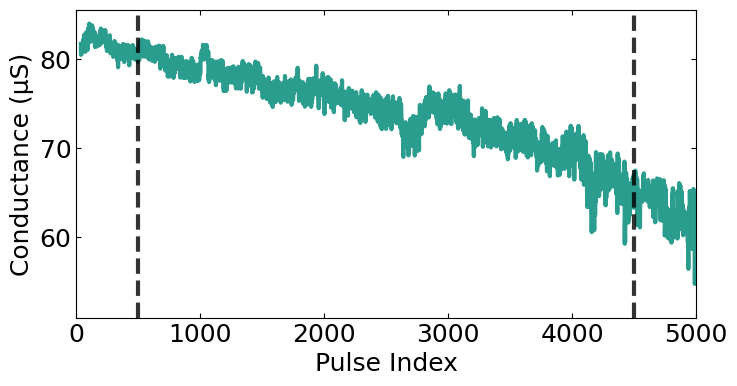

In [13]:
example_wr_cycle = pd.read_csv("data/devices_arraywr2/R63_60.csv")
example_wr_cycle = example_wr_cycle[example_wr_cycle["pattern"] == "WEAK_RESET"]

plt.figure(figsize=(8,4))
plt.plot(1e6/example_wr_cycle.iloc[:5000]["resistance"], c="C2")
plt.xlim(0, 5000)
plt.axvline(500, color="k", linestyle="--", alpha=.8)
plt.axvline(4500, color="k", linestyle="--", alpha=.8)
plt.xlabel("Pulse Index")
plt.ylabel("Conductance (µS)")

plt.savefig("plots_out/_example_conductance.svg", dpi=300, bbox_inches="tight")
1e6/example_wr_cycle.iloc[:5000]["resistance"].iloc[500], 1e6/example_wr_cycle.iloc[:5000]["resistance"].iloc[4500]

Text(0, 0.5, 'Conductance (µS)')

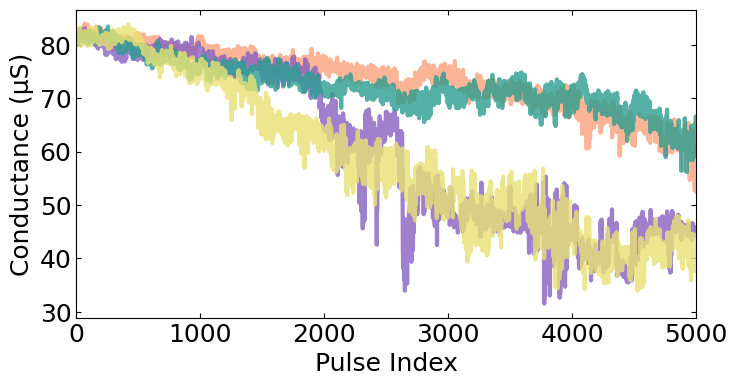

In [14]:
gss_per_dev = np.load("plots_out/_buffer_endurance_pulses.npy").reshape(4, -1, 5000)
plt.figure(figsize=(8,4))
plt.plot(1e6*gss_per_dev[0, 0], c="C0", alpha=.8)
plt.plot(1e6*gss_per_dev[0, 10], c="C1", alpha=.8)
plt.plot(1e6*gss_per_dev[0, 20], c="C2", alpha=.8)
plt.plot(1e6*gss_per_dev[0, 30], c="C3", alpha=.8)
plt.xlim(0, 5000)
plt.xlabel("Pulse Index")
plt.ylabel("Conductance (µS)")

In [15]:
# Early switchs

def first_elem_or(arr, default=-1):
  return default if len(arr) == 0 else arr[0]

dv_thresh = 25

sel_devs = gss_per_dev[0, -50:]
devs_dv = 1e6*np.diff(sel_devs, axis=1)
early_switch_idxs = np.apply_along_axis(
  lambda x: first_elem_or((x > dv_thresh).nonzero()[0]),
  axis=-1,
  arr=devs_dv
)
np.count_nonzero(early_switch_idxs>0) / sel_devs.shape[0] * 100

2.0

##### Reducing WL voltage: can we get sub-one volt fully-open gates with our techno node?

Text(0.5, 0, 'Pulse Index')

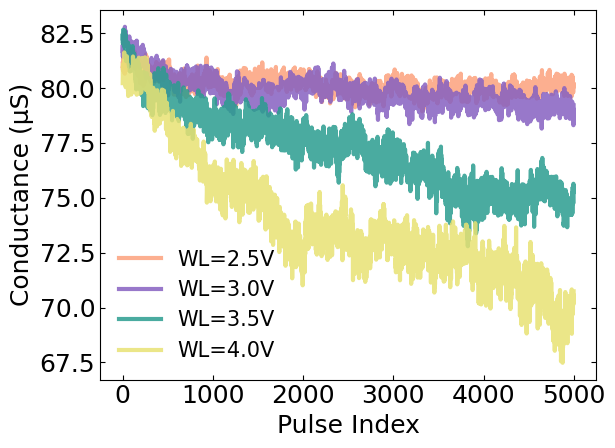

In [17]:
subonevolt_wl_exp_1V = "02be2839-f8b5-4167-bfd3-f1bbbe885bad"
subonevolt_wl_exp_25V = "3ac6758a-544e-44ff-88f8-eb435bd180c1"
subonevolt_wl_exp_35V = "f017b2a4-ad26-4955-ab87-0612a9f1cf76"
subonevolt_wl_exp_30V = "145a2d58-cf5e-4de0-b232-dcbffb00a9f5"
subonevolt_wl_exp_40V = "56b5fb82-b2f4-4e92-95a7-3c17d9d862f8"
df_sov_wl = pd.read_csv("data/devices_arraywr2/R00_01.csv")
df_sov_wl_25V = df_sov_wl[(df_sov_wl["pattern"] == "WEAK_RESET") & (df_sov_wl["exp_uuid"] == subonevolt_wl_exp_25V)]
df_sov_wl_30V = df_sov_wl[(df_sov_wl["pattern"] == "WEAK_RESET") & (df_sov_wl["exp_uuid"] == subonevolt_wl_exp_30V)]
df_sov_wl_35V = df_sov_wl[(df_sov_wl["pattern"] == "WEAK_RESET") & (df_sov_wl["exp_uuid"] == subonevolt_wl_exp_35V)]
df_sov_wl_40V = df_sov_wl[(df_sov_wl["pattern"] == "WEAK_RESET") & (df_sov_wl["exp_uuid"] == subonevolt_wl_exp_40V)]

sov_wl_gss_25V = 1e6 / df_sov_wl_25V["resistance"].to_numpy().reshape(-1, 5000)
sov_wl_gss_30V = 1e6 / df_sov_wl_30V["resistance"].to_numpy().reshape(-1, 5000)
sov_wl_gss_35V = 1e6 / df_sov_wl_35V["resistance"].to_numpy().reshape(-1, 5000)
sov_wl_gss_40V = 1e6 / df_sov_wl_40V["resistance"].to_numpy().reshape(-1, 5000)

plt.plot(sov_wl_gss_25V.mean(axis=0), alpha=.85, c="C0", label="WL=2.5V")
plt.plot(sov_wl_gss_30V.mean(axis=0), alpha=.85, c="C1", label="WL=3.0V")
plt.plot(sov_wl_gss_35V.mean(axis=0), alpha=.85, c="C2", label="WL=3.5V")
plt.plot(sov_wl_gss_40V.mean(axis=0), alpha=.85, c="C3", label="WL=4.0V")
plt.legend()
plt.ylabel("Conductance (µS)")
plt.xlabel("Pulse Index")